# Radiomics experiments and results

The historical experiments include repeated CT scans under different LNDb identifiers. The binary calibration/test experiments in section 11 exclude the confirmed copies.

All calculations below use saved predictions and models. No models are retrained. Each exported CSV retains the saved run directory in its `run` column.

## Tables used in the main notebook

Run this notebook from top to bottom to generate the tables displayed in [radiomics_analysis.ipynb](radiomics_analysis.ipynb). Reports are saved under `data/processed/`.

| Main section | Calculation and export | Output |
|---|---|---|
| 6.1 Spheres versus segmentation | [8.2 Matched region comparison](#82-spheres-versus-segmentation-on-shared-nodules) | `radiomics_region_comparison.csv` |
| 6.1 Five-class classification | [8.1 Five-class table](#81-five-class-table-for-the-main-notebook) | `radiomics_five_class_results.csv` |
| 6.2 Default binary decisions | [11.1 Default decisions](#111-default-decisions) | `radiomics_binary_default_results.csv` |
| 6.2 Duplicate-excluded binary ROC | [11.8 ROC and zero-FN points](#118-duplicate-excluded-roc-for-the-main-notebook) | `radiomics_binary_roc_points.csv` and `radiomics_binary_roc.png` |
| 6.2 Calibrated binary decisions | [11.6 Binary comparison](#116-binary-table-for-the-main-notebook) | `radiomics_binary_results.csv` |
| 6.3 Regression | [7.1 Regression table](#71-regression-table-for-the-main-notebook) | `radiomics_regression_results.csv` |
| 7.1 Remaining binary errors | [11.7 Paired errors](#117-baseline-versus-filtered-and-tuned-balanced-rf) | `radiomics_binary_errors.csv` |
| 7.2 Feature selection | [10.1 Feature-selection table](#101-feature-selection-table-for-the-main-notebook) | `radiomics_feature_selection_results.csv` |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "configs/paths.yaml").exists(), "Run from the repository root or notebooks/."
sys.path.insert(0, str(ROOT))

from src.modeling import feature_inventory, EXCLUDED_LNDB_IDS, metrics

KEYS = ["LNDbID", "FindingID"]
LIDC_KEYS = ["patient_id", "series_uid", "nodule_id"]
CLASSES = [1, 2, 3, 4, 5]
print("Repository:", ROOT)
print("Duplicate CTs excluded only with --exclude-duplicate-lndb:", sorted(EXCLUDED_LNDB_IDS))

Repository: /home/jp/Documents/por-definir-ds
Duplicate CTs excluded only with --exclude-duplicate-lndb: [181, 182, 183, 184, 185, 188, 189, 194, 195, 198, 226]


## 1. What features do we have?

Training data only. Each row counts nodules with extracted features in that CSV.

In [2]:
from src.modeling import feature_inventory

#for 2.5D, each slice has its own row.
display(feature_inventory(ROOT / "data"))

,dataset,region,method,CSV,nodules,rows,features
0,LIDC,circle,2.5D,lidc_circle_r11_5slice_hu.csv,2637,13185,930
1,LIDC,circle,2D,lidc_circle_r11_bw10_hu.csv,2637,2637,930
2,LIDC,circle,2D,lidc_circle_r11_clipped.csv,2637,2637,930
3,LIDC,circle,2D,lidc_circle_r11_hu.csv,2637,2637,930
4,LIDC,circle,2D,lidc_circle_r14_clipped.csv,2637,2637,930
5,LIDC,circle,2D,lidc_circle_r14_hu.csv,2637,2637,930
6,LIDC,circle,2D,lidc_circle_r17_clipped.csv,2637,2637,930
7,LIDC,circle,2D,lidc_circle_r17_hu.csv,2637,2637,930
8,LIDC,circle,2D,lidc_circle_r21_clipped.csv,2637,2637,930
9,LIDC,circle,2D,lidc_circle_r21_hu.csv,2637,2637,930


## 2. What did we change between experiments?

### Circle radii

We start with circles extracted from the original HU values and validate on all 765 LNDb training nodules. Consensus applies to segmentation masks, not circles.

We used the P95, P97 and P99 nodule-size percentiles to choose circle radii for LNDb and LIDC.

| Percentile | LNDb radius | LIDC radius |
|---|---:|---:|
| P95 | 6 mm | 14 mm |
| P97 | 7 mm | 17 mm |
| P99 | 11 mm | 21 mm |

Because nodule sizes differ between the datasets, we tried using each dataset’s radius. We also tried using the same radius in both datasets, taking the LNDb value, to see whether keeping the extraction region the same size works better. We additionally tried 11 mm in LIDC with 6 mm in LNDb.

In [3]:
def display_models(models):
    scores = {}
    for choice, name in models.items():
        table = pd.read_csv(ROOT / "models" / name / "metrics.csv")
        scores[choice] = table.loc[
            table["fold"].eq("overall_oof"),
            ["balanced_accuracy", "macro_f1", "qwk", "mae"],
        ].iloc[0]

    display(pd.DataFrame(scores).T.round(3))

In [4]:
models = {
    "same radius: LNDb 6, LIDC 6": "rf_lidc_circle_r6_hu_lndb_circle_r6_hu_balanced",
    "same radius: LNDb 7, LIDC 7": "rf_lidc_circle_r7_hu_lndb_circle_r7_hu_balanced",
    "same radius: LNDb 11, LIDC 11": "rf_lidc_circle_r11_hu_lndb_circle_r11_hu_balanced",
    "P95: LNDb 6, LIDC 14": "rf_circle_r14_r6_balanced_5class",
    "P97: LNDb 7, LIDC 17": "rf_circle_r17_r7_balanced_5class",
    "P99: LNDb 11, LIDC 21": "rf_lidc_circle_r21_hu_lndb_circle_r11_hu_balanced",
    "extra: LNDb 6, LIDC 11": "rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced",
}

display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"same radius: LNDb 6, LIDC 6",0.382,0.383,0.443,0.725
"same radius: LNDb 7, LIDC 7",0.388,0.385,0.445,0.724
"same radius: LNDb 11, LIDC 11",0.360,0.369,0.351,0.790
"P95: LNDb 6, LIDC 14",0.409,0.422,0.435,0.698
"P97: LNDb 7, LIDC 17",0.375,0.388,0.435,0.690
"P99: LNDb 11, LIDC 21",0.345,0.371,0.352,0.736
"extra: LNDb 6, LIDC 11",0.408,0.429,0.442,0.685


We thought P99 might help by including more of the perinodular region, but both P99 choices had lower balanced accuracy than P95. Larger circles may also include nearby vessels and other tissue. These scores cannot tell us why the predictions changed. The P95 14/6 mm model and the extra 11/6 mm model are nearly tied on balanced accuracy (0.409 and 0.408). The 11/6 mm model has lower MAE (0.685 versus 0.698).

### Does clipping help?

As described in the preprocessing notebook, we also extracted features after clipping CT values to [-1000, 400] HU. We compare this with the original HU values using the same 14/6 mm circles, model and 765 LNDb nodules.

In [5]:
clipping_models = {
    "14/6 mm, original HU": "rf_circle_r14_r6_balanced_5class",
    "14/6 mm, clipped HU": "rf_circle_r14_r6_clipped_balanced_5class",
}

display_models(clipping_models)

,balanced_accuracy,macro_f1,qwk,mae
"14/6 mm, original HU",0.409,0.422,0.435,0.698
"14/6 mm, clipped HU",0.356,0.363,0.421,0.707


Clipping did not help this 14/6 mm model. Balanced accuracy fell from 0.409 to 0.356, and MAE rose from 0.698 to 0.707. The original HU values also gave higher macro F1 and QWK here.

### Do circles or 2D segmentations work better?

The radius comparisons above used all 765 LNDb nodules. Segmentation masks are available only for nodules ≥3 mm, so this comparison uses 622 LNDb nodules. We retrained the 14/6 mm circle model on exactly the same LNDb and LIDC nodules as the 2D, 50% consensus segmentation model.

In [6]:
models = {
    "circle, 14/6 mm": "rf_circle_r14_r6_ge3_c50_population_balanced",
    "2D segmentation, 50% consensus": "rf_segmentation_2d_c50_bw25_available_balanced",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"circle, 14/6 mm",0.397,0.427,0.414,0.711
"2D segmentation, 50% consensus",0.399,0.414,0.529,0.650


Balanced accuracy is nearly the same (0.397 for circles and 0.399 for segmentation). Segmentation has higher QWK (0.529 versus 0.414) and lower MAE (0.650 versus 0.711), while circles have higher macro F1 (0.427 versus 0.414). Circles use the slice nearest the centroid, whereas segmentation uses the slice with the largest mask area, so the region and selected slice both change.

### What changes with 2D mask consensus?

A higher consensus requires more readers to include a pixel in the mask. With 75% and 100% consensus, some masks become too small to extract features. The 25% and 50% models use 622 LNDb nodules. The 75% and 100% models use 614, so their overall scores also reflect a change in the training and validation population.

In [7]:
models = {
    "25%": "rf_segmentation_2d_c25_bw25_available_balanced",
    "50%": "rf_segmentation_2d_c50_bw25_available_balanced",
    "75%": "rf_segmentation_2d_c75_bw25_available_balanced",
    "100%": "rf_segmentation_2d_c100_bw25_available_balanced",
}
display_models(models)

lndb_ids = []
for level in (75, 100):
    lidc = pd.read_csv(ROOT / "data" / f"lidc_segmentation_2d_c{level}_hu.csv")
    lndb = pd.read_csv(ROOT / "models" / models[f"{level}%"] / "validation_predictions.csv")
    lndb_ids.append(set(zip(lndb.LNDbID, lndb.FindingID)))
    print(f"{level}%: {len(lidc)} LIDC, {len(lndb)} LNDb")

print("Same LNDb nodules:", lndb_ids[0] == lndb_ids[1])

,balanced_accuracy,macro_f1,qwk,mae
25%,0.388,0.399,0.493,0.666
50%,0.399,0.414,0.529,0.650
75%,0.379,0.394,0.503,0.674
100%,0.375,0.388,0.484,0.686


75%: 2630 LIDC, 614 LNDb


100%: 2628 LIDC, 614 LNDb
Same LNDb nodules: True


The 50% consensus model has the highest balanced accuracy, macro F1 and QWK, and the lowest MAE in this table. The 75% and 100% models also lose eight LNDb nodules and some LIDC nodules during extraction. Their score differences cannot be attributed to the consensus level alone.

### Does 3D segmentation help?

Both models use 50% consensus masks and validate on the same 622 LNDb nodules. The 2D model extracts features from one axial slice, while the 3D model uses the full mask volume. The 3D extraction also includes one more LIDC training nodule.

In [8]:
models = {
    "2D": "rf_segmentation_2d_c50_bw25_available_balanced",
    "3D": "rf_segmentation_3d_c50_bw25_ge3_balanced",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
2D,0.399,0.414,0.529,0.650
3D,0.428,0.446,0.523,0.632


The 3D model has higher balanced accuracy (0.428 versus 0.399) and macro F1 (0.446 versus 0.414), and lower MAE (0.632 versus 0.650). The 2D model has slightly higher QWK (0.529 versus 0.523). Since the LIDC training populations differ by one nodule, this does not isolate the effect of 2D versus 3D extraction completely.

### Does a 3D sphere help?

At 11/6 mm, compare a circle on one slice with a 3D sphere around the same centroid. Both models use all 765 LNDb training nodules.

In [9]:
models = {
    "2D circle, 11/6 mm": "rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced",
    "3D sphere, 11/6 mm": "rf_sphere_bw25_balanced",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"2D circle, 11/6 mm",0.408,0.429,0.442,0.685
"3D sphere, 11/6 mm",0.399,0.416,0.489,0.655


The sphere has higher QWK (0.489 versus 0.442) and lower MAE (0.655 versus 0.685), but lower balanced accuracy (0.399 versus 0.408).

### Do spheres or 3D segmentations work better?

To compare a sphere with the 3D, 50% consensus segmentation, restrict the sphere model to the same 622 LNDb nodules. The full-population sphere score above is not directly comparable with this segmentation score.

In [10]:
models = {
    "3D sphere, LNDb ≥3 mm": "rf_sphere_bw25_ge3_balanced",
    "3D segmentation, 50%": "rf_segmentation_3d_c50_bw25_ge3_balanced",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"3D sphere, LNDb ≥3 mm",0.401,0.428,0.475,0.680
"3D segmentation, 50%",0.428,0.446,0.523,0.632


On these 622 nodules, 3D segmentation improves balanced accuracy (0.428 versus 0.401), QWK (0.523 versus 0.475) and MAE (0.632 versus 0.680) over the sphere. Unlike the sphere, it uses the provided nodule mask.

### Do five circle slices help?

We also trained a five-class RF using five adjacent circle slices instead of one. Each training nodule contributes five rows, although validation still counts each nodule once.

In [11]:
models = {
    "one circle slice, 11/6 mm": "rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced",
    "five circle slices, 11/6 mm": "rf_circle_r11_r6_5slice_balanced",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"one circle slice, 11/6 mm",0.408,0.429,0.442,0.685
"five circle slices, 11/6 mm",0.353,0.373,0.396,0.708


For five-class prediction, five slices reduce balanced accuracy from 0.408 to 0.353 and QWK from 0.442 to 0.396. The binary result is a separate question below.

### Does a smaller bin width help?

As described in the radiomics decisions notebook, bin width groups CT values for texture features. Here we compare 25 HU with 10 HU using the same 11/6 mm circles and 765 LNDb nodules.

In [12]:
models = {
    "25 HU": "rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced",
    "10 HU": "rf_circle_r11_r6_bw10_balanced",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
25 HU,0.408,0.429,0.442,0.685
10 HU,0.370,0.382,0.437,0.695


For these 11/6 mm circles, 25 HU gives higher balanced accuracy (0.408 versus 0.370), macro F1 and QWK, and lower MAE (0.685 versus 0.695) than 10 HU. This comparison does not establish the best bin width for other regions or radii.

## 3. Does training on LIDC or changing class balance help?

We keep the LNDb circle radius at 6 mm and compare training on LNDb alone with training on LNDb plus LIDC, using 14 mm circles for LIDC. Both models are evaluated on the same 765 LNDb nodules.

In [13]:
models = {
    "LNDb only, 6 mm": "rf_lndb_circle_r6_hu_balanced",
    "LNDb + LIDC, 14/6 mm": "rf_circle_r14_r6_balanced_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"LNDb only, 6 mm",0.409,0.430,0.446,0.681
"LNDb + LIDC, 14/6 mm",0.409,0.422,0.435,0.698


No big difference.


The five-class labels are uneven. Among the 765 LNDb nodules, 254 are class 2 but only 18 are class 5. We first compare RF with and without class weights, then class weights, SMOTE and Balanced RF on the same 14/6 mm circles.

For 3D spheres and 50% consensus segmentations, compare the three balancing methods separately on the same 622 LNDb nodules ≥3 mm. The sphere results here use the ≥3 mm model, not the 765-nodule sphere model.

In [14]:
models = {
    "no class weights": "rf_circle_r14_r6_unweighted_5class",
    "balanced class weights": "rf_circle_r14_r6_balanced_5class",
}
display_models(models)
models = {
    "LNDb only, no class weights": "rf_lndb_circle_r6_hu",
    "LNDb only, balanced": "rf_lndb_circle_r6_hu_balanced",
}
display_models(models)
models = {
    "class weights": "rf_circle_r14_r6_balanced_5class",
    "SMOTE": "rf_circle_r14_r6_smote_5class",
    "balanced RF": "brf_circle_r14_r6_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
no class weights,0.385,0.402,0.467,0.667
balanced class weights,0.409,0.422,0.435,0.698


,balanced_accuracy,macro_f1,qwk,mae
"LNDb only, no class weights",0.379,0.393,0.458,0.672
"LNDb only, balanced",0.409,0.430,0.446,0.681


,balanced_accuracy,macro_f1,qwk,mae
class weights,0.409,0.422,0.435,0.698
SMOTE,0.412,0.399,0.439,0.736
balanced RF,0.426,0.323,0.414,0.809


In [15]:
models = {
    "class weights, 3D sphere": "rf_sphere_bw25_ge3_balanced",
    "SMOTE, 3D sphere": "rf_sphere_ge3_smote_5class",
    "Balanced RF, 3D sphere": "brf_sphere_ge3_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"class weights, 3D sphere",0.401,0.428,0.475,0.680
"SMOTE, 3D sphere",0.452,0.436,0.500,0.722
"Balanced RF, 3D sphere",0.484,0.385,0.477,0.788


In [16]:
models = {
    "class weights, 3D segmentation": "rf_segmentation_3d_c50_bw25_ge3_balanced",
    "SMOTE, 3D segmentation": "rf_segmentation_3d_c50_ge3_smote_5class",
    "Balanced RF, 3D segmentation": "brf_segmentation_3d_c50_ge3_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"class weights, 3D segmentation",0.428,0.446,0.523,0.632
"SMOTE, 3D segmentation",0.445,0.435,0.504,0.698
"Balanced RF, 3D segmentation",0.480,0.416,0.519,0.743


With 14/6 mm circles, Balanced RF has the highest balanced accuracy among these three balancing methods, but class-weighted RF has higher macro F1 and lower MAE. On both 3D regions, Balanced RF again has the highest balanced accuracy (0.484 for spheres and 0.480 for segmentations), while class-weighted RF has lower MAE (0.680 and 0.632). No balancing method wins on every metric.

## 4. Do fewer features help?

First compare all 14/6 mm circle features with top 100, top 500, Original-only and normalized pairs for each balancing method. Original-only uses features from the CT image without additional filters. Normalized pairs keeps other features, but removes a measure's non-normalized version when its `Normalized` version exists.

Then compare all features with top 100, 500 and 1000 for class-weighted RF on 11/6 mm 3D spheres and 50% consensus 3D segmentations. Balanced RF feature selection is also shown where trained. The 3D models use the same 622 LNDb nodules ≥3 mm, while circles use 765 nodules. Top-k uses [ANOVA F scores](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.f_classif.html) and is selected inside each training fold.

In [17]:
models = {
    "all, class weights": "rf_circle_r14_r6_balanced_5class",
    "top 100, class weights": "rf_circle_r14_r6_balanced_k100_5class",
    "top 500, class weights": "rf_circle_r14_r6_balanced_k500_5class",
    "Original only, class weights": "rf_circle_r14_r6_balanced_original_5class",
    "normalized pairs, class weights": "rf_circle_r14_r6_balanced_normalized_pairs_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"all, class weights",0.409,0.422,0.435,0.698
"top 100, class weights",0.355,0.370,0.428,0.697
"top 500, class weights",0.396,0.416,0.432,0.699
"Original only, class weights",0.362,0.382,0.434,0.718
"normalized pairs, class weights",0.395,0.425,0.429,0.693


In [18]:
models = {
    "all, SMOTE": "rf_circle_r14_r6_smote_5class",
    "top 100, SMOTE": "rf_circle_r14_r6_smote_k100_5class",
    "top 500, SMOTE": "rf_circle_r14_r6_smote_k500_5class",
    "Original only, SMOTE": "rf_circle_r14_r6_smote_original_5class",
    "normalized pairs, SMOTE": "rf_circle_r14_r6_smote_normalized_pairs_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"all, SMOTE",0.412,0.399,0.439,0.736
"top 100, SMOTE",0.340,0.323,0.424,0.766
"top 500, SMOTE",0.409,0.389,0.433,0.749
"Original only, SMOTE",0.359,0.329,0.403,0.841
"normalized pairs, SMOTE",0.405,0.396,0.430,0.750


In [19]:
models = {
    "all, Balanced RF": "brf_circle_r14_r6_5class",
    "top 100, Balanced RF": "brf_circle_r14_r6_k100_5class",
    "top 500, Balanced RF": "brf_circle_r14_r6_k500_5class",
    "Original only, Balanced RF": "brf_circle_r14_r6_original_5class",
    "normalized pairs, Balanced RF": "brf_circle_r14_r6_normalized_pairs_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"all, Balanced RF",0.426,0.323,0.414,0.809
"top 100, Balanced RF",0.420,0.334,0.435,0.783
"top 500, Balanced RF",0.417,0.313,0.402,0.825
"Original only, Balanced RF",0.424,0.315,0.390,0.843
"normalized pairs, Balanced RF",0.434,0.332,0.419,0.799


In [20]:
models = {
    "all, 3D sphere": "rf_sphere_bw25_ge3_balanced",
    "top 100, 3D sphere": "rf_sphere_ge3_balanced_k100_5class",
    "top 500, 3D sphere": "rf_sphere_ge3_balanced_k500_5class",
    "top 1000, 3D sphere": "rf_sphere_ge3_balanced_k1000_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"all, 3D sphere",0.401,0.428,0.475,0.680
"top 100, 3D sphere",0.414,0.443,0.485,0.670
"top 500, 3D sphere",0.410,0.432,0.492,0.677
"top 1000, 3D sphere",0.380,0.401,0.456,0.704


In [21]:
models = {
    "all, 3D sphere Balanced RF": "brf_sphere_ge3_5class",
    "top 100, 3D sphere Balanced RF": "brf_sphere_ge3_k100_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"all, 3D sphere Balanced RF",0.484,0.385,0.477,0.788
"top 100, 3D sphere Balanced RF",0.466,0.387,0.482,0.778


In [22]:
models = {
    "all, 3D segmentation RF": "rf_segmentation_3d_c50_bw25_ge3_balanced",
    "top 100, 3D segmentation RF": "rf_segmentation_3d_c50_ge3_balanced_k100_5class",
    "top 500, 3D segmentation RF": "rf_segmentation_3d_c50_ge3_balanced_k500_5class",
    "top 1000, 3D segmentation RF": "rf_segmentation_3d_c50_ge3_balanced_k1000_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"all, 3D segmentation RF",0.428,0.446,0.523,0.632
"top 100, 3D segmentation RF",0.425,0.447,0.504,0.638
"top 500, 3D segmentation RF",0.412,0.430,0.495,0.662
"top 1000, 3D segmentation RF",0.409,0.426,0.504,0.656


In [23]:
models = {
    "all, 3D segmentation Balanced RF": "brf_segmentation_3d_c50_ge3_5class",
    "top 100, 3D segmentation Balanced RF": "brf_segmentation_3d_c50_ge3_k100_5class",
    "top 500, 3D segmentation Balanced RF": "brf_segmentation_3d_c50_ge3_k500_5class",
    "top 1000, 3D segmentation Balanced RF": "brf_segmentation_3d_c50_ge3_k1000_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"all, 3D segmentation Balanced RF",0.480,0.416,0.519,0.743
"top 100, 3D segmentation Balanced RF",0.456,0.415,0.520,0.719
"top 500, 3D segmentation Balanced RF",0.446,0.400,0.505,0.759
"top 1000, 3D segmentation Balanced RF",0.468,0.411,0.515,0.752


With circles, top-k selection does not improve balanced accuracy for class-weighted RF or SMOTE. Balanced RF improves from 0.426 to 0.434 with normalized pairs, but still has higher MAE than class-weighted RF.

For 3D spheres, class-weighted RF improves across all four metrics with top 100 (balanced accuracy 0.414 versus 0.401 with all features). For 3D segmentation, all features have the highest balanced accuracy within both RF settings (0.428 with class weights and 0.480 with Balanced RF). Feature reduction helps the sphere RF, but not the 3D segmentation models on balanced accuracy.

## 5. How do Balanced RF and XGBoost compare?

Compare both models using all features within each region: 14/6 mm circles on 765 LNDb nodules, then 11/6 mm 3D spheres and 50% consensus 3D segmentations on the same 622 LNDb nodules ≥3 mm. Balanced RF undersamples each tree, while XGBoost uses balanced sample weights, so this tests the complete model settings rather than the algorithm alone.

In [24]:
models = {
    "Balanced RF, 14/6 mm circles": "brf_circle_r14_r6_5class",
    "XGBoost, 14/6 mm circles": "xgboost_circle_r14_r6_balanced_5class",
}
display_models(models)

models = {
    "Balanced RF, 3D sphere": "brf_sphere_ge3_5class",
    "XGBoost, 3D sphere": "xgboost_sphere_ge3_balanced_5class",
}
display_models(models)

models = {
    "Balanced RF, 3D segmentation": "brf_segmentation_3d_c50_ge3_5class",
    "XGBoost, 3D segmentation": "xgboost_segmentation_3d_c50_ge3_balanced_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"Balanced RF, 14/6 mm circles",0.426,0.323,0.414,0.809
"XGBoost, 14/6 mm circles",0.436,0.386,0.489,0.718


,balanced_accuracy,macro_f1,qwk,mae
"Balanced RF, 3D sphere",0.484,0.385,0.477,0.788
"XGBoost, 3D sphere",0.442,0.410,0.502,0.725


,balanced_accuracy,macro_f1,qwk,mae
"Balanced RF, 3D segmentation",0.480,0.416,0.519,0.743
"XGBoost, 3D segmentation",0.455,0.430,0.529,0.712


With circles, XGBoost outperforms Balanced RF on all four metrics. With 3D spheres and segmentations, Balanced RF has higher balanced accuracy (0.484 and 0.480 versus 0.442 and 0.455), while XGBoost has higher macro F1 and QWK and lower MAE. These are matched comparisons within each region, not across the 765- and 622-nodule populations.

### Earlier RF tuning at 11/6 mm

The saved comparison below tunes ordinary RF on 11/6 mm circles and also shows a separate normalized-pairs feature test. It does not tune the 14/6 mm or 3D Balanced RF and XGBoost models.

In [25]:
models = {
    "ordinary RF": "rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced",
    "tuned RF": "rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced_tuned",
    "normalized pairs": "rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced_normalized_pairs",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
ordinary RF,0.408,0.429,0.442,0.685
tuned RF,0.406,0.414,0.447,0.686
normalized pairs,0.404,0.433,0.433,0.685


Tuning gives almost the same balanced accuracy as ordinary RF (0.406 versus 0.408), with a small QWK increase (0.447 versus 0.442). Normalized pairs give slightly higher macro F1 (0.433 versus 0.429) but lower balanced accuracy and QWK. MAE is 0.685 for both ordinary RF and normalized pairs.

### 7.1 Regression table for the main notebook

Inputs are the three Ridge runs listed in `ridge_models`, using `models/<run>/validation_predictions.csv`. Continuous errors are measured against the unrounded reader mean. QWK uses rounded five-class predictions. All three runs have the same 622 findings, targets and folds.

This exports `data/processed/radiomics_regression_results.csv` for main section 6.3. The detailed alert-conversion table above remains on its separate 471-nodule population.

In [29]:
regression_report = pd.DataFrame(regression_rows)
regression_report["run"] = regression_report.region.map(ridge_models)
regression_report["nodules"] = 622
regression_report["region"] = regression_report.region.map({
    "circle (14/6 mm)": "Circle",
    "3D sphere (11/6 mm)": "Sphere",
    "3D segmentation (50%)": "Segmentation",
})
regression_report = regression_report[[
    "region", "run", "nodules", "continuous MAE", "continuous RMSE",
    "rounded five-class QWK",
]]
report_path = ROOT / "data/processed/radiomics_regression_results.csv"
regression_report.to_csv(report_path, index=False)
display(regression_report.set_index("region").drop(columns=["run", "nodules"]).round(3))
print("Saved:", report_path.relative_to(ROOT))

,continuous MAE,continuous RMSE,rounded five-class QWK
region,,,
Circle,0.805,1.053,0.378
Sphere,0.916,2.175,0.418
Segmentation,0.821,1.140,0.427


Saved: data/processed/radiomics_regression_results.csv


### 8.1 Five-class table for the main notebook

Inputs are saved `models/<run>/validation_predictions.csv` files. Only five-class runs matching all 765 findings, targets and folds in `data/processed/lndb_nodule_targets.csv` and `lndb_patient_folds.csv` enter this ranking. Metrics are recalculated from the predictions.

This exports the full ranking to `data/processed/radiomics_five_class_results.csv`. Main section 6.1 displays its first five rows. The `run` column identifies the source folder for every row. Display names are labels only and do not affect ranking.

In [31]:
keys = KEYS + ["fold"]
reference_targets = pd.read_csv(
    ROOT / "data/processed/lndb_nodule_targets.csv"
).rename(columns={"NoduleID": "FindingID"})
reference_folds = pd.read_csv(ROOT / "data/processed/lndb_patient_folds.csv")
reference = reference_targets.merge(
    reference_folds, on="LNDbID", validate="many_to_one"
).set_index(keys).sort_index()["target_classification_mean"]
assert len(reference) == 765 and reference.index.is_unique

rows = []
for file in sorted((ROOT / "models").glob("*/validation_predictions.csv")):
    if "grid4" in file.parent.name and not (file.parent / "tuning.csv").exists():
        continue  # Earlier directories named grid4 were not actually tuned.
    predictions = pd.read_csv(file)
    if len(predictions) != 765 or "target_classification_mean" not in predictions:
        continue
    assert not predictions.duplicated(KEYS).any(), file.parent.name
    predictions = predictions.set_index(keys).sort_index()
    if not predictions.target_classification_mean.equals(reference):
        continue
    assert predictions.prediction.isin(CLASSES).all(), file.parent.name
    rows.append({
        "model": file.parent.name,
        **metrics(reference, predictions.prediction),
    })

all_nodules = add_combined_score(pd.DataFrame(rows).set_index("model"))
model_labels = {
    "rf_sphere_smote_5class": "RF + SMOTE, sphere",
    "rf_sphere_smote_aux": "RF + SMOTE + auxiliary targets, sphere",
    "rf_sphere_balanced_k100_5class": "Class-weighted RF, sphere, top 100",
    "expert_sphere_gldm": "RF + SMOTE, sphere, GLDM features",
    "expert_sphere_firstorder": "RF + SMOTE, sphere, intensity features",
}
five_class_report = all_nodules.sort_values(
    "combined score", ascending=False
).rename_axis("run").reset_index()
five_class_report.insert(
    0, "model", five_class_report.run.map(model_labels).fillna(five_class_report.run)
)
five_class_report["nodules"] = 765
five_class_report = five_class_report.rename(columns={
    "balanced_accuracy": "balanced accuracy", "macro_f1": "macro F1",
    "qwk": "QWK", "mae": "MAE",
})
report_path = ROOT / "data/processed/radiomics_five_class_results.csv"
five_class_report.to_csv(report_path, index=False)
display(five_class_report.set_index("model").drop(columns=["run", "nodules"]).head(5).round(3))
print("Saved:", report_path.relative_to(ROOT))

,balanced accuracy,macro F1,QWK,MAE,combined score
model,,,,,
"RF + SMOTE, sphere",0.458,0.429,0.539,0.672,0.439
"RF + SMOTE + auxiliary targets, sphere",0.449,0.424,0.528,0.678,0.430
"Class-weighted RF, sphere, top 100",0.407,0.428,0.513,0.654,0.423
"RF + SMOTE, sphere, GLDM features",0.438,0.412,0.504,0.697,0.414
"RF + SMOTE, sphere, intensity features",0.436,0.406,0.514,0.702,0.414


Saved: data/processed/radiomics_five_class_results.csv


### 8.2 Spheres versus segmentation on shared nodules

This table compares four training settings using 3D spheres and 50% consensus 3D segmentations. All eight runs use the same 622 LNDb findings, reader targets and patient folds. The historical runs include the duplicate CT copies.

The run mapping below identifies each input `models/<run>/validation_predictions.csv`. Metrics are recalculated and checked against that run's `metrics.csv`.

Output: `data/processed/radiomics_region_comparison.csv`, displayed first in main section 6.1. Its `run` column retains the source directory.

In [32]:
region_runs = {
    ("Class-weighted RF", "Sphere"): "rf_sphere_bw25_ge3_balanced",
    ("Class-weighted RF", "Segmentation"): "rf_segmentation_3d_c50_bw25_ge3_balanced",
    ("RF + SMOTE", "Sphere"): "rf_sphere_ge3_smote_5class",
    ("RF + SMOTE", "Segmentation"): "rf_segmentation_3d_c50_ge3_smote_5class",
    ("Balanced RF", "Sphere"): "brf_sphere_ge3_5class",
    ("Balanced RF", "Segmentation"): "brf_segmentation_3d_c50_ge3_5class",
    ("Class-weighted XGBoost", "Sphere"): "xgboost_sphere_ge3_balanced_5class",
    ("Class-weighted XGBoost", "Segmentation"): "xgboost_segmentation_3d_c50_ge3_balanced_5class",
}
region_reference = five_class_validation.set_index(KEYS).sort_index()
region_rows = []
for (model, region), run in region_runs.items():
    predictions = pd.read_csv(
        ROOT / "models" / run / "validation_predictions.csv"
    ).set_index(KEYS).sort_index()
    assert predictions.index.is_unique and len(predictions) == 622
    pd.testing.assert_frame_equal(
        region_reference, predictions[["fold", "target_classification_mean"]],
        check_dtype=False,
    )
    result = metrics(predictions.target_classification_mean, predictions.prediction)
    stored = pd.read_csv(ROOT / "models" / run / "metrics.csv")
    overall = stored.loc[stored.fold.eq("overall_oof"), list(result)]
    assert len(overall) == 1
    np.testing.assert_allclose(overall.iloc[0], list(result.values()), atol=1e-12, rtol=0)
    region_rows.append({
        "model": model, "region": region, "run": run,
        "nodules": len(predictions), **result,
    })

region_report = add_combined_score(pd.DataFrame(region_rows)).rename(columns={
    "balanced_accuracy": "balanced accuracy", "macro_f1": "macro F1",
    "qwk": "QWK", "mae": "MAE",
})
report_path = ROOT / "data/processed/radiomics_region_comparison.csv"
region_report.to_csv(report_path, index=False)
display(region_report.set_index(["model", "region"]).drop(columns=["run", "nodules"]).round(3))
print("Saved:", report_path.relative_to(ROOT))

balanced accuracy  macro F1    QWK  \
model                  region                                             
Class-weighted RF      Sphere                    0.401     0.428  0.475   
                       Segmentation              0.428     0.446  0.523   
RF + SMOTE             Sphere                    0.452     0.436  0.500   
                       Segmentation              0.445     0.435  0.504   
Balanced RF            Sphere                    0.484     0.385  0.477   
                       Segmentation              0.480     0.416  0.519   
Class-weighted XGBoost Sphere                    0.442     0.410  0.502   
                       Segmentation              0.455     0.430  0.529   

                                       MAE  combined score  
model                  region                               
Class-weighted RF      Sphere        0.680           0.406  
                       Segmentation  0.632           0.441  
RF + SMOTE             Sphere        0.722           0.416  
                       Segmentation  0.698           0.422  
Balanced RF            Sphere        0.788           0.389  
                       Segmentation  0.743           0.418  
Class-weighted XGBoost Sphere        0.725           0.407  
                       Segmentation  0.712           0.425

Saved: data/processed/radiomics_region_comparison.csv


### 10.1 Feature-selection table for the main notebook

Inputs are `validation_predictions.csv` and `metrics.csv` in the two run folders listed below. Both runs use class-weighted RF, the same 622 findings and the same saved folds. Only the feature filter changes.

This exports `data/processed/radiomics_feature_selection_results.csv` for main section 7.2, including missed ratings 4–5 alongside the overall metrics.

In [39]:
selection_runs = {
    "All features": "rf_segmentation_3d_c50_bw25_ge3_balanced",
    "Volume correlation ≤0.7": "rf_segmentation_3d_c50_ge3_maxsize0.7",
}
selection_rows = []
selection_reference = None
for label, run in selection_runs.items():
    predictions = pd.read_csv(
        ROOT / "models" / run / "validation_predictions.csv"
    ).set_index(KEYS).sort_index()
    assert predictions.index.is_unique and len(predictions) == 622
    cohort = predictions[["fold", "target_classification_mean"]]
    if selection_reference is None:
        selection_reference = cohort
    pd.testing.assert_frame_equal(selection_reference, cohort, check_dtype=False)
    result = metrics(predictions.target_classification_mean, predictions.prediction)
    stored = pd.read_csv(ROOT / "models" / run / "metrics.csv")
    overall = stored.loc[stored.fold.eq("overall_oof"), list(result)]
    assert len(overall) == 1
    np.testing.assert_allclose(overall.iloc[0], list(result.values()), atol=1e-12, rtol=0)
    high = predictions.target_classification_mean.ge(4)
    selection_rows.append({
        "model": label, "run": run, "nodules": len(predictions), **result,
        "rated 4–5": int(high.sum()),
        "missed ratings 4–5": int((high & predictions.prediction.lt(4)).sum()),
    })

feature_report = add_combined_score(pd.DataFrame(selection_rows)).rename(columns={
    "balanced_accuracy": "balanced accuracy", "macro_f1": "macro F1",
    "qwk": "QWK", "mae": "MAE",
})
report_path = ROOT / "data/processed/radiomics_feature_selection_results.csv"
feature_report.to_csv(report_path, index=False)
display(feature_report.set_index("model").drop(columns=["run", "nodules"]).round(3))
print("Saved:", report_path.relative_to(ROOT))

,balanced accuracy,macro F1,QWK,MAE,rated 4–5,missed ratings 4–5,combined score
model,,,,,,,
All features,0.428,0.446,0.523,0.632,88,53,0.441
Volume correlation ≤0.7,0.447,0.466,0.527,0.627,88,55,0.453


Saved: data/processed/radiomics_feature_selection_results.csv


### 11.6 Binary table for the main notebook

Inputs are `models/segmentation_binary_calibration/validation_predictions.csv` and `models/segmentation_binary_diameter07_tuned/validation_predictions.csv`. Baseline rows include the three binary-trained recipes. Filtered/tuned rows include XGBoost and Balanced RF.

Each row uses the same 459 findings, targets and patient folds, excluding the confirmed CT copies. Predictions retain their saved calibration thresholds. Metrics are recalculated from those predictions and checked against the saved overall metrics. AUC uses the saved test scores.

This exports `data/processed/radiomics_binary_results.csv` for the second table in main section 6.2. The `run` column identifies the directory and `recipe` identifies the model within its prediction CSV.

The copies were excluded from LNDb before assigning rows to training, calibration and test roles. The exclusion is enabled by `exclude_duplicate_lndb=True` in `src/binary_evaluation.py` and `src/binary_tuning.py`. The former records the excluded IDs in `models/segmentation_binary_calibration/excluded_ct_copies.csv`, and the latter records them in each run's `settings.json`. These experiments have 459 binary-labelled nodules (85 positive), compared with 471 (91 positive) in the historical default-decision comparison.

In [49]:
binary_report_runs = {
    "Baseline": "segmentation_binary_calibration",
    "Filtered + tuned": "segmentation_binary_diameter07_tuned",
}
recipe_labels = {
    "Binary XGBoost, all features": "XGBoost",
    "Binary Balanced RF, all features": "Balanced RF",
    "Binary RF, intensity": "RF, intensity only",
}
canonical_test = reference_folds.to_frame().join(readers[[LABEL]])
canonical_test = canonical_test.loc[
    ~canonical_test.index.get_level_values("LNDbID").isin(EXCLUDED_LNDB_IDS)
].sort_index()
assert len(canonical_test) == 459 and canonical_test[LABEL].sum() == 85
binary_report_rows, binary_report_tables = [], {}
for variant, directory in binary_report_runs.items():
    predictions = pd.read_csv(ROOT / "models" / directory / "validation_predictions.csv")
    saved_metrics = pd.read_csv(ROOT / "models" / directory / "metrics.csv")
    for recipe, label in recipe_labels.items():
        group = predictions.loc[predictions.model.eq(recipe)].set_index(KEYS).sort_index()
        if variant == "Filtered + tuned" and recipe == "Binary RF, intensity":
            continue
        assert group.index.is_unique
        pd.testing.assert_frame_equal(
            canonical_test, group[["fold", LABEL]], check_dtype=False,
        )
        assert group.prediction.eq(group.score.ge(group.threshold)).all()
        result = binary_report_scores(group[LABEL], group.prediction, group.score)
        stored = saved_metrics.loc[
            saved_metrics.model.eq(recipe) & saved_metrics.fold.eq("overall_oof")
        ]
        assert len(stored) == 1
        for column in ["nodules", "TP", "FN", "TN", "FP", "accuracy", "balanced_accuracy"]:
            np.testing.assert_allclose(result[column], stored.iloc[0][column], atol=1e-12, rtol=0)
        binary_report_rows.append({
            "model": label, "variant": variant, "run": directory, "recipe": recipe,
            "positives": int(group[LABEL].sum()), **result,
        })
        binary_report_tables[variant, label] = group

binary_report = pd.DataFrame(binary_report_rows).rename(columns={
    "balanced_accuracy": "balanced accuracy", "sensitivity": "recall",
})
report_path = ROOT / "data/processed/radiomics_binary_results.csv"
binary_report.to_csv(report_path, index=False)
display(binary_report.set_index(["model", "variant"])[[
    "FN", "FP", "accuracy", "balanced accuracy", "macro F1",
    "recall", "specificity", "precision", "AUC",
]].round(3))
print("Saved:", report_path.relative_to(ROOT))

,,FN,FP,accuracy,balanced accuracy,macro F1,recall,specificity,precision,AUC
model,variant,,,,,,,,,
XGBoost,Baseline,4,161,0.641,0.761,0.608,0.953,0.570,0.335,0.877
Balanced RF,Baseline,3,212,0.532,0.699,0.517,0.965,0.433,0.279,0.859
"RF, intensity only",Baseline,5,200,0.553,0.703,0.534,0.941,0.465,0.286,0.862
XGBoost,Filtered + tuned,5,169,0.621,0.745,0.591,0.941,0.548,0.321,0.871
Balanced RF,Filtered + tuned,2,196,0.569,0.726,0.549,0.976,0.476,0.297,0.865


Saved: data/processed/radiomics_binary_results.csv


### 11.7 Baseline versus filtered and tuned Balanced RF

The paired predictions below use the same 459 findings. The first table counts recovered positives, newly missed positives, removed false alerts and new false alerts. The second lists the remaining FN for the filtered/tuned model.

Ratings come from `data/processed/lndb_ge3_nodule_targets.csv`. Equivalent-sphere diameters are calculated from `original_shape_MeshVolume` in `data/lndb_ge3_segmentation_3d_c50_hu.csv`.

This exports `data/processed/radiomics_binary_errors.csv` for main section 7.1.

In [50]:
baseline_brf = binary_report_tables["Baseline", "Balanced RF"]
tuned_brf = binary_report_tables["Filtered + tuned", "Balanced RF"]
positive = baseline_brf[LABEL].eq(1)
negative = baseline_brf[LABEL].eq(0)
changes = pd.Series({
    "positives recovered": int((positive & baseline_brf.prediction.eq(0) & tuned_brf.prediction.eq(1)).sum()),
    "positives newly missed": int((positive & baseline_brf.prediction.eq(1) & tuned_brf.prediction.eq(0)).sum()),
    "false alerts removed": int((negative & baseline_brf.prediction.eq(1) & tuned_brf.prediction.eq(0)).sum()),
    "new false alerts": int((negative & baseline_brf.prediction.eq(0) & tuned_brf.prediction.eq(1)).sum()),
})
display(changes.to_frame("nodules"))

remaining = tuned_brf.loc[
    tuned_brf[LABEL].eq(1) & tuned_brf.prediction.eq(0),
    ["fold", "score", "threshold"],
].join(readers[["ratings", "target_regression_mean"]], validate="one_to_one")
remaining = remaining.join(shape[["original_shape_MeshVolume"]], validate="one_to_one")
assert remaining.notna().all().all()
remaining["diameter (mm)"] = 2 * (
    3 * remaining.original_shape_MeshVolume / (4 * np.pi)
) ** (1 / 3)
remaining = remaining.rename(columns={"target_regression_mean": "reader mean"})
remaining["run"] = binary_report_runs["Filtered + tuned"]
remaining["recipe"] = "Binary Balanced RF, all features"
remaining = remaining.drop(columns="original_shape_MeshVolume").reset_index()
report_path = ROOT / "data/processed/radiomics_binary_errors.csv"
remaining.to_csv(report_path, index=False)
display(remaining.set_index(KEYS)[[
    "ratings", "reader mean", "diameter (mm)", "score", "threshold",
]].round(3))
print("Saved:", report_path.relative_to(ROOT))

,nodules
positives recovered,1
positives newly missed,0
false alerts removed,22
new false alerts,6


,,ratings,reader mean,diameter (mm),score,threshold
LNDbID,FindingID,,,,,
53,2,"[5.0, 5.0]",5.0,4.040,0.082,0.123
119,1,[4.0],4.0,5.183,0.157,0.273


Saved: data/processed/radiomics_binary_errors.csv


Filtering and tuning recover one baseline Balanced RF miss, remove 22 false alerts and introduce six new false alerts. The remaining two FN include a nodule rated 5 by both readers. The high-sensitivity objective has not been reached on the separate evaluation folds.

### 11.8 Duplicate-excluded ROC for the main notebook

Inputs are the five saved test-score tables already checked in section 11.6: three baseline recipes from `models/segmentation_binary_calibration/validation_predictions.csv` and two filtered/tuned recipes from `models/segmentation_binary_diameter07_tuned/validation_predictions.csv`. All have the same 459 findings, including 85 positives, with confirmed CT copies excluded before fitting and fold evaluation.

Each curve uses the saved `score` and `target_binary_mean` columns. Its marked point uses the lowest positive score on those evaluated rows, with an alert for score ≥ threshold. These zero-FN points are retrospective. The separately calibrated decisions remain in the section 11.6 table.

Outputs for main section 6.2:
- `data/processed/radiomics_binary_roc.png`: the ROC figure.
- `data/processed/radiomics_binary_roc_points.csv`: zero-FN thresholds and metrics, with source `run` and `recipe` columns.

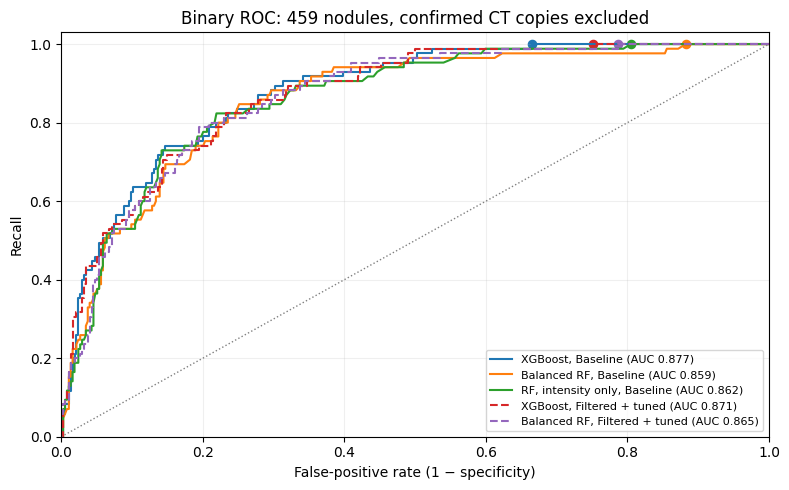

,,threshold,FN,FP,accuracy,specificity
model,variant,,,,,
XGBoost,Baseline,0.0168,0,249,0.4575,0.3342
Balanced RF,Baseline,0.0620,0,330,0.2810,0.1176
"RF, intensity only",Baseline,0.0440,0,301,0.3442,0.1952
XGBoost,Filtered + tuned,0.0255,0,281,0.3878,0.2487
Balanced RF,Filtered + tuned,0.0823,0,294,0.3595,0.2139


Zero-observed-FN ROC candidate: XGBoost, Baseline
Saved: data/processed/radiomics_binary_roc.png and data/processed/radiomics_binary_roc_points.csv


In [51]:
roc_point_rows = []
fig, ax = plt.subplots(figsize=(8, 5))
for (variant, model), group in binary_report_tables.items():
    pd.testing.assert_frame_equal(
        canonical_test, group[["fold", LABEL]], check_dtype=False,
    )
    point = zero_fn_summary(group[LABEL], group.score)
    point["macro F1"] = f1_score(
        group[LABEL], group.score.ge(point["threshold"]),
        labels=[0, 1], average="macro", zero_division=0,
    )
    recipe = next(name for name, label in recipe_labels.items() if label == model)
    roc_point_rows.append({
        "model": model, "variant": variant, "run": binary_report_runs[variant],
        "recipe": recipe, "positives": int(group[LABEL].sum()),
        "threshold selection": "evaluated rows", **point,
    })
    fpr, tpr, _ = roc_curve(group[LABEL], group.score, drop_intermediate=False)
    line, = ax.plot(
        fpr, tpr, linestyle="-" if variant == "Baseline" else "--",
        label=f"{model}, {variant} (AUC {point['AUC']:.3f})",
    )
    ax.scatter(1 - point["specificity"], 1, color=line.get_color(), s=35)

ax.plot([0, 1], [0, 1], linestyle=":", color="gray", linewidth=1)
ax.set(
    xlabel="False-positive rate (1 − specificity)", ylabel="Recall",
    title="Binary ROC: 459 nodules, confirmed CT copies excluded",
    xlim=(0, 1), ylim=(0, 1.03),
)
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.2)
fig.tight_layout()
figure_path = ROOT / "data/processed/radiomics_binary_roc.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

roc_points = pd.DataFrame(roc_point_rows).rename(columns={
    "balanced_accuracy": "balanced accuracy", "sensitivity": "recall",
})
report_path = ROOT / "data/processed/radiomics_binary_roc_points.csv"
roc_points.to_csv(report_path, index=False)
display(roc_points.set_index(["model", "variant"])[[
    "threshold", "FN", "FP", "accuracy", "specificity",
]].round(4))
zero_fn_choice = roc_points.sort_values("specificity", ascending=False).iloc[0]
assert zero_fn_choice.FN == 0
print(f"Zero-observed-FN ROC candidate: {zero_fn_choice.model}, {zero_fn_choice.variant}")
print("Saved:", figure_path.relative_to(ROOT), "and", report_path.relative_to(ROOT))